# BTC/USDT 30-Minute Direction Prediction

Predict whether the **next bar's open price** will be higher or lower than the
**current bar's open price**, and by how many percent, using a LightGBM model
trained on engineered technical features from the 30-minute BTC/USDT bar data.

**Target**
- `y_cls`: 1 if `open[t+1] > open[t]`, else 0 (binary direction)
- `y_reg`: `(open[t+1] - open[t]) / open[t] * 100` (signed percent move)

**Leakage guard**: since `open[t+1]` is essentially the current bar's close,
the target for row `t` is driven by bar `t`'s own price action. All features
used to predict it are therefore built from data available **through bar
`t-1`** only (the feature matrix is shifted forward by one bar relative to
the target) — no information from bar `t` or later ever reaches the model.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_absolute_error, mean_squared_error,
)

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

## 1. Load data

In [4]:
DATA_PATH = "./data/market_bars_30m_with_backfill.csv"

raw = pd.read_csv(DATA_PATH, parse_dates=["bar_open_time_utc"])
raw = raw.sort_values("bar_open_time_utc").reset_index(drop=True)

df = raw[["bar_open_time_utc", "open", "high", "low", "close", "volume", "quote_volume", "trade_count"]].copy()
df = df.set_index("bar_open_time_utc")

print(df.shape)
print(df.index.min(), "->", df.index.max())
df.head()

(52608, 7)
2023-09-02 00:00:00+00:00 -> 2026-09-01 23:30:00+00:00


,open,high,low,close,volume,quote_volume,trade_count
bar_open_time_utc,,,,,,,
2023-09-02 00:00:00+00:00,25805.04,25834.00,25790.34,25832.72,267.87778,6.913767e+06,10100
2023-09-02 00:30:00+00:00,25832.73,25840.00,25781.40,25789.12,293.94001,7.586668e+06,10226
2023-09-02 01:00:00+00:00,25789.12,25814.00,25773.95,25799.57,287.33803,7.411593e+06,10529
2023-09-02 01:30:00+00:00,25799.58,25815.55,25773.67,25773.68,217.45912,5.608911e+06,9365
2023-09-02 02:00:00+00:00,25773.68,25795.69,25766.28,25795.69,231.76478,5.974187e+06,9430


## 2. Feature engineering

A broad set of technical/statistical features computed purely from OHLCV history:
price returns at multiple lags, rolling return moments, moving-average
deviations, MACD, RSI, Bollinger Bands, ATR, stochastic oscillator, candle
shape, volume/trade-count anomalies, momentum (ROC), rolling win-rate, and
cyclical time-of-day / day-of-week encodings.

In [5]:
o, h, l, c, v = df["open"], df["high"], df["low"], df["close"], df["volume"]
qv = df["quote_volume"]
tc = df["trade_count"]

feat = pd.DataFrame(index=df.index)
ret1 = np.log(c / c.shift(1))

# --- lagged log returns ---
for lag in [1, 2, 3, 6, 12, 24, 48, 96]:
    feat[f"ret_lag_{lag}"] = np.log(c / c.shift(lag))

# --- rolling return moments ---
for w in [6, 12, 24, 48, 96, 192]:
    feat[f"ret_mean_{w}"] = ret1.rolling(w).mean()
    feat[f"ret_std_{w}"] = ret1.rolling(w).std()
    feat[f"ret_skew_{w}"] = ret1.rolling(w).skew()

# --- moving-average deviation ---
for w in [5, 10, 20, 50, 100, 200]:
    sma = c.rolling(w).mean()
    ema = c.ewm(span=w, adjust=False).mean()
    feat[f"close_over_sma_{w}"] = c / sma - 1
    feat[f"close_over_ema_{w}"] = c / ema - 1

# --- MACD ---
ema12 = c.ewm(span=12, adjust=False).mean()
ema26 = c.ewm(span=26, adjust=False).mean()
macd = ema12 - ema26
macd_signal = macd.ewm(span=9, adjust=False).mean()
feat["macd"] = macd / c
feat["macd_signal"] = macd_signal / c
feat["macd_hist"] = (macd - macd_signal) / c


def rsi(series, w=14):
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1 / w, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1 / w, adjust=False).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    return 100 - (100 / (1 + rs))


for w in [7, 14, 21]:
    feat[f"rsi_{w}"] = rsi(c, w)

# --- Bollinger Bands ---
for w in [20, 50]:
    sma = c.rolling(w).mean()
    std = c.rolling(w).std()
    upper, lower = sma + 2 * std, sma - 2 * std
    feat[f"bb_pctb_{w}"] = (c - lower) / (upper - lower)
    feat[f"bb_width_{w}"] = (upper - lower) / sma

# --- ATR ---
prev_close = c.shift(1)
tr = pd.concat([h - l, (h - prev_close).abs(), (l - prev_close).abs()], axis=1).max(axis=1)
for w in [14, 28]:
    atr = tr.ewm(alpha=1 / w, adjust=False).mean()
    feat[f"atr_{w}"] = atr / c

# --- stochastic oscillator ---
for w in [14]:
    lowest, highest = l.rolling(w).min(), h.rolling(w).max()
    k = 100 * (c - lowest) / (highest - lowest)
    feat[f"stoch_k_{w}"] = k
    feat[f"stoch_d_{w}"] = k.rolling(3).mean()

# --- candle shape ---
feat["body"] = (c - o) / o
feat["upper_wick"] = (h - np.maximum(o, c)) / o
feat["lower_wick"] = (np.minimum(o, c) - l) / o
feat["hl_range"] = (h - l) / c

# --- volume / activity anomalies ---
vol_ma = v.rolling(20).mean()
feat["vol_ratio_20"] = v / vol_ma
feat["vol_chg_1"] = np.log(v.replace(0, np.nan) / v.shift(1).replace(0, np.nan))
feat["vol_z_20"] = (v - vol_ma) / v.rolling(20).std()
feat["dollar_vol_ratio_20"] = qv / qv.rolling(20).mean()
feat["trade_count_z_20"] = (tc - tc.rolling(20).mean()) / tc.rolling(20).std()

# --- momentum ---
for w in [3, 6, 12, 24]:
    feat[f"roc_{w}"] = c.pct_change(w)

# --- rolling win-rate ---
up_bar = (c > o).astype(float)
for w in [10, 20, 50]:
    feat[f"up_rate_{w}"] = up_bar.rolling(w).mean()

# --- cyclical time encodings ---
hour = df.index.hour + df.index.minute / 60
feat["hour_sin"] = np.sin(2 * np.pi * hour / 24)
feat["hour_cos"] = np.cos(2 * np.pi * hour / 24)
dow = df.index.dayofweek
feat["dow_sin"] = np.sin(2 * np.pi * dow / 7)
feat["dow_cos"] = np.cos(2 * np.pi * dow / 7)

print("num features:", feat.shape[1])
feat.tail()

num features: 72


,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_6,ret_lag_12,ret_lag_24,ret_lag_48,ret_lag_96,ret_mean_6,ret_std_6,ret_skew_6,ret_mean_12,ret_std_12,ret_skew_12,ret_mean_24,ret_std_24,ret_skew_24,ret_mean_48,ret_std_48,ret_skew_48,ret_mean_96,ret_std_96,ret_skew_96,ret_mean_192,ret_std_192,...,bb_width_50,atr_14,atr_28,stoch_k_14,stoch_d_14,body,upper_wick,lower_wick,hl_range,vol_ratio_20,vol_chg_1,vol_z_20,dollar_vol_ratio_20,trade_count_z_20,roc_3,roc_6,roc_12,roc_24,up_rate_10,up_rate_20,up_rate_50,hour_sin,hour_cos,dow_sin,dow_cos
bar_open_time_utc,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-09-01 21:30:00+00:00,0.000293,-0.003066,-0.002441,0.000744,-0.009125,-0.009072,-0.022450,-0.018500,0.000124,0.002034,-0.873599,-0.000760,0.002104,-0.087242,-0.000378,0.001946,-0.364258,-0.000468,0.002426,-0.966958,-0.000193,0.002647,-0.547736,-0.000010,0.002138,...,0.029681,0.004549,0.004311,45.226297,44.967814,0.000293,0.000795,0.001990,0.003077,0.384387,-0.753742,-1.016392,0.382361,-0.820486,-0.002438,0.000744,-0.009083,-0.009031,0.5,0.45,0.48,-0.608761,0.793353,0.781831,0.62349
2026-09-01 22:00:00+00:00,-0.001806,-0.001513,-0.004873,-0.003761,-0.007125,-0.012044,-0.021690,-0.016856,-0.000627,0.001696,-0.848688,-0.000594,0.001912,-0.008095,-0.000502,0.001938,-0.202315,-0.000452,0.002415,-0.990629,-0.000176,0.002631,-0.559828,-0.000034,0.002133,...,0.030082,0.004454,0.004276,38.717340,40.766974,-0.001804,0.001304,0.000000,0.003114,0.427345,0.099029,-0.929747,0.425506,-1.088347,-0.004861,-0.003754,-0.007100,-0.011972,0.5,0.45,0.46,-0.500000,0.866025,0.781831,0.62349
2026-09-01 22:30:00+00:00,0.002618,0.000812,0.001105,-0.000491,-0.004158,-0.009731,-0.016927,-0.014747,-0.000082,0.002151,-0.556076,-0.000347,0.002126,-0.050814,-0.000405,0.002035,-0.161885,-0.000353,0.002441,-1.034308,-0.000154,0.002646,-0.563622,-0.000033,0.002134,...,0.030022,0.004434,0.004267,54.885604,46.276414,0.002621,0.001168,0.000545,0.004322,0.557348,0.252168,-0.701089,0.555068,-1.059710,0.001106,-0.000491,-0.004150,-0.009684,0.6,0.45,0.46,-0.382683,0.923880,0.781831,0.62349
2026-09-01 23:00:00+00:00,0.001588,0.004206,0.002400,-0.000041,-0.001512,-0.007880,-0.015179,-0.003627,-0.000007,0.002209,-0.587187,-0.000126,0.002182,-0.332400,-0.000328,0.002075,-0.232317,-0.000316,0.002457,-1.049807,-0.000038,0.002468,-0.244596,-0.000019,0.002136,...,0.029996,0.004276,0.004190,75.068779,56.223908,0.001589,0.000000,0.000725,0.002311,0.354026,-0.508757,-0.954567,0.353166,-1.139766,0.002403,-0.000041,-0.001510,-0.007849,0.7,0.50,0.48,-0.258819,0.965926,0.781831,0.62349
2026-09-01 23:30:00+00:00,0.000545,0.002133,0.004750,-0.000122,0.002239,-0.008486,-0.014643,-0.003133,-0.000020,0.002205,-0.565487,0.000187,0.001958,-0.611038,-0.000354,0.002060,-0.211293,-0.000305,0.002460,-1.059621,-0.000033,0.002469,-0.250636,-0.000027,0.002131,...,0.030052,0.004202,0.004156,78.308716,69.421033,0.000545,0.002573,0.000166,0.003282,0.783134,0.698778,-0.342805,0.783887,-0.780450,0.004762,-0.000122,0.002242,-0.008450,0.7,0.50,0.50,-0.130526,0.991445,0.781831,0.62349


## 3. Target and leakage-safe alignment

In [6]:
target_pct = (o.shift(-1) - o) / o * 100   # % move from open[t] to open[t+1]
target_up = (target_pct > 0).astype(int)

# shift the ENTIRE feature matrix forward by 1 bar so that predicting target[t]
# only ever uses information available through bar t-1
X_all = feat.shift(1)

dataset = pd.concat([X_all, target_up.rename("y_cls"), target_pct.rename("y_reg")], axis=1)
dataset = dataset.dropna()

feature_cols = [col for col in dataset.columns if col not in ("y_cls", "y_reg")]
print("rows:", len(dataset), " features:", len(feature_cols))
dataset["y_cls"].value_counts(normalize=True)

rows: 52407  features: 72


y_cls
1    0.507222
0    0.492778
Name: proportion, dtype: float64

## 4. Time-based train / validation / test split

Chronological split (no shuffling) — 70% train / 15% validation / 15% test —
since shuffling would leak future information into training for a time series.

In [7]:
X = dataset[feature_cols]
y_cls = dataset["y_cls"]
y_reg = dataset["y_reg"]

n = len(dataset)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, X_val, X_test = X.iloc[:train_end], X.iloc[train_end:val_end], X.iloc[val_end:]
yc_train, yc_val, yc_test = y_cls.iloc[:train_end], y_cls.iloc[train_end:val_end], y_cls.iloc[val_end:]
yr_train, yr_val, yr_test = y_reg.iloc[:train_end], y_reg.iloc[train_end:val_end], y_reg.iloc[val_end:]

print("train:", X_train.shape, dataset.index[0], "->", dataset.index[train_end - 1])
print("val:  ", X_val.shape, dataset.index[train_end], "->", dataset.index[val_end - 1])
print("test: ", X_test.shape, dataset.index[val_end], "->", dataset.index[-1])

train: (36684, 72) 2023-09-06 04:00:00+00:00 -> 2025-10-09 09:30:00+00:00
val:   (7861, 72) 2025-10-09 10:00:00+00:00 -> 2026-03-22 04:00:00+00:00
test:  (7862, 72) 2026-03-22 04:30:00+00:00 -> 2026-09-01 23:00:00+00:00


## 5. Hyperparameter search (walk-forward cross-validation)

Rather than trust a single train/val/test split, hyperparameters are selected
by average AUC across 5 expanding-window folds (`TimeSeriesSplit`), which
also gives a robustness check on how stable the edge is over time.

In [8]:
from sklearn.model_selection import TimeSeriesSplit
import lightgbm as lgb
from sklearn.metrics import roc_auc_score  

tscv = TimeSeriesSplit(n_splits=5)
candidates = [
    dict(learning_rate=0.01, num_leaves=15, colsample_bytree=0.7),
    dict(learning_rate=0.01, num_leaves=31, colsample_bytree=0.8),
    dict(learning_rate=0.03, num_leaves=15, colsample_bytree=0.7),
    dict(learning_rate=0.03, num_leaves=31, colsample_bytree=0.8),
]

Xv = X.values
yv = y_cls.values

cv_results = []
for cand in candidates:
    fold_aucs = []
    for train_idx, test_idx in tscv.split(Xv):
        cut = int(len(train_idx) * 0.85)
        tr_idx, va_idx = train_idx[:cut], train_idx[cut:]
        m = lgb.LGBMClassifier(
            n_estimators=2000, min_child_samples=50, subsample=0.8, subsample_freq=1,
            reg_alpha=0.1, reg_lambda=0.1, objective="binary",
            random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **cand,
        )
        m.fit(
            Xv[tr_idx], yv[tr_idx],
            eval_set=[(Xv[va_idx], yv[va_idx])], eval_metric="auc",
            callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)],
        )
        p = m.predict_proba(Xv[test_idx])[:, 1]
        fold_aucs.append(roc_auc_score(yv[test_idx], p))
    cv_results.append((cand, np.mean(fold_aucs), np.std(fold_aucs), fold_aucs))
    print(cand, "mean AUC:", round(np.mean(fold_aucs), 4), "std:", round(np.std(fold_aucs), 4))

best_params, best_mean_auc, *_ = max(cv_results, key=lambda r: r[1])
print("\nBest config:", best_params, "mean walk-forward AUC:", round(best_mean_auc, 4))

/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Document

{'learning_rate': 0.01, 'num_leaves': 15, 'colsample_bytree': 0.7} mean AUC: 0.5416 std: 0.0081


/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Document

{'learning_rate': 0.01, 'num_leaves': 31, 'colsample_bytree': 0.8} mean AUC: 0.5416 std: 0.0069


/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Document

{'learning_rate': 0.03, 'num_leaves': 15, 'colsample_bytree': 0.7} mean AUC: 0.5401 std: 0.007


/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Users/suppanatp/Document

{'learning_rate': 0.03, 'num_leaves': 31, 'colsample_bytree': 0.8} mean AUC: 0.5383 std: 0.007

Best config: {'learning_rate': 0.01, 'num_leaves': 31, 'colsample_bytree': 0.8} mean walk-forward AUC: 0.5416


## 6. Final classifier: train and evaluate on held-out test set

In [9]:
clf = lgb.LGBMClassifier(
    n_estimators=3000, min_child_samples=50, subsample=0.8, subsample_freq=1,
    reg_alpha=0.1, reg_lambda=0.1, objective="binary",
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **best_params,
)
clf.fit(
    X_train, yc_train,
    eval_set=[(X_val, yc_val)], eval_metric="auc",
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
)
print("best_iteration:", clf.best_iteration_)

proba_val = clf.predict_proba(X_val)[:, 1]
proba_test = clf.predict_proba(X_test)[:, 1]

/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best_iteration: 55


In [20]:
def report(y_true, proba, threshold, label):
    pred = (proba > threshold).astype(int)
    auc = roc_auc_score(y_true, proba)
    prec = precision_score(y_true, pred)
    rec = recall_score(y_true, pred)
    f1 = f1_score(y_true, pred)
    print(f"=== {label} (threshold={threshold:.3f}) ===")
    print(f"AUC:       {auc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1:        {f1:.4f}")
    print("Confusion matrix (rows=true, cols=pred):")
    print(confusion_matrix(y_true, pred))
    print(classification_report(y_true, pred, digits=4))
    return auc, prec, rec, f1


baseline_pred = np.ones(len(yc_test))
print("Baseline (always predict UP) accuracy:", (baseline_pred == yc_test.values).mean())
print()

report(yc_test, proba_test, 0.5, "Test set @ default threshold")

Baseline (always predict UP) accuracy: 0.5006359704909692

=== Test set @ default threshold (threshold=0.500) ===
AUC:       0.5338
Precision: 0.5153
Recall:    0.6768
F1:        0.5851
Confusion matrix (rows=true, cols=pred):
[[1420 2506]
 [1272 2664]]
              precision    recall  f1-score   support

           0     0.5275    0.3617    0.4291      3926
           1     0.5153    0.6768    0.5851      3936

    accuracy                         0.5195      7862
   macro avg     0.5214    0.5193    0.5071      7862
weighted avg     0.5214    0.5195    0.5072      7862



(0.5337596850162974, 0.5152804642166344, 0.676829268292683, 0.5851087195255875)

### Threshold sweep

The probability output has limited separation given AUC ~0.53, so maximizing
F1 alone tends to degenerate toward "always predict up" (near-100% recall,
~50% precision — no better than the base rate). Sweeping the threshold shows
the real precision/recall trade-off: raising the cutoff buys higher precision
at the cost of covering far fewer bars.

In [21]:
rows = []
for t in np.arange(0.46, 0.54, 0.01):
    pred = (proba_test > t).astype(int)
    coverage = pred.mean()  # fraction of bars where the model calls "up"
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(yc_test, pred, zero_division=0),
        "recall": recall_score(yc_test, pred, zero_division=0),
        "f1": f1_score(yc_test, pred, zero_division=0),
        "coverage": coverage,
    })
pd.DataFrame(rows).round(4)

,threshold,precision,recall,f1,coverage
0,0.46,0.5007,0.9992,0.6671,0.9991
1,0.47,0.5016,0.9929,0.6665,0.9910
2,0.48,0.5051,0.9632,0.6627,0.9546
3,0.49,0.5102,0.8552,0.6391,0.8391
4,0.50,0.5153,0.6768,0.5851,0.6576
5,0.51,0.5227,0.5112,0.5169,0.4896
6,0.52,0.5294,0.3338,0.4095,0.3157
7,0.53,0.5684,0.1542,0.2426,0.1358
8,0.54,0.5369,0.0203,0.0392,0.0190


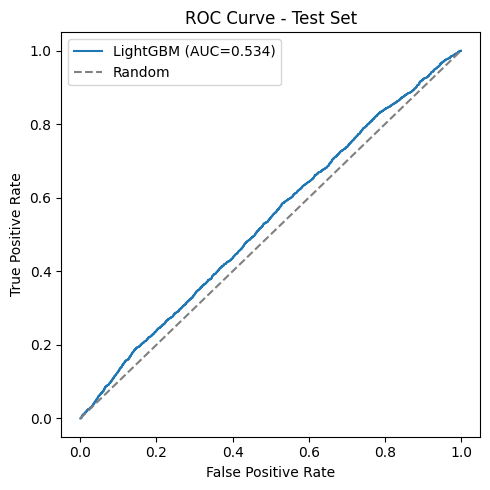

In [22]:
fpr, tpr, _ = roc_curve(yc_test, proba_test)
test_auc = roc_auc_score(yc_test, proba_test)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"LightGBM (AUC={test_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Test Set")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Feature importance

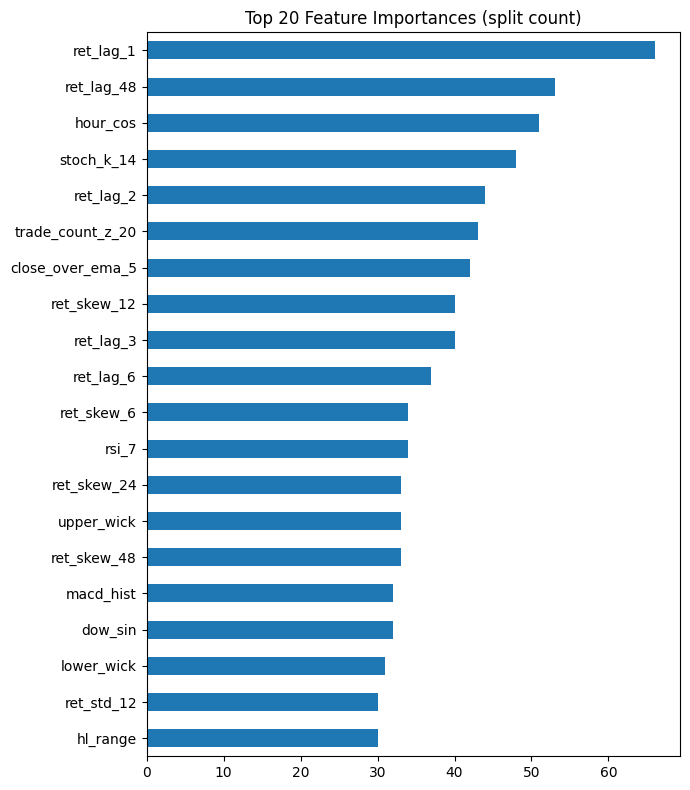

ret_lag_1           66
ret_lag_48          53
hour_cos            51
stoch_k_14          48
ret_lag_2           44
trade_count_z_20    43
close_over_ema_5    42
ret_skew_12         40
ret_lag_3           40
ret_lag_6           37
ret_skew_6          34
rsi_7               34
ret_skew_24         33
upper_wick          33
ret_skew_48         33
macd_hist           32
dow_sin             32
lower_wick          31
ret_std_12          30
hl_range            30
dtype: int32

In [23]:
importance = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(7, 8))
importance.head(20).iloc[::-1].plot(kind="barh")
plt.title("Top 20 Feature Importances (split count)")
plt.tight_layout()
plt.show()

importance.head(20)

## 8. Magnitude regression

A second LightGBM regressor predicts the signed percent move itself
(`y_reg`), so predictions can be reported as "up/down by X%" rather than
direction alone. Compared against a naive baseline that always predicts 0%.

In [24]:
reg = lgb.LGBMRegressor(
    n_estimators=3000, min_child_samples=50, subsample=0.8, subsample_freq=1,
    reg_alpha=0.1, reg_lambda=0.1, objective="regression",
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **best_params,
)
reg.fit(
    X_train, yr_train,
    eval_set=[(X_val, yr_val)], eval_metric="l2",
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
)

pred_reg = reg.predict(X_test)
mae = mean_absolute_error(yr_test, pred_reg)
rmse = mean_squared_error(yr_test, pred_reg) ** 0.5
naive_mae = mean_absolute_error(yr_test, np.zeros_like(yr_test))
dir_acc_from_reg = ((pred_reg > 0).astype(int) == yc_test.values).mean()

print(f"MAE:  {mae:.4f}%")
print(f"RMSE: {rmse:.4f}%")
print(f"Naive (predict 0%) MAE: {naive_mae:.4f}%")
print(f"Direction accuracy implied by regressor sign: {dir_acc_from_reg:.4f}")

/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE:  0.1928%
RMSE: 0.2986%
Naive (predict 0%) MAE: 0.1927%
Direction accuracy implied by regressor sign: 0.4991


In [36]:
pred_df = pd.DataFrame({
    "y_true": yr_test,
    "y_pred": pred_reg,
    "y_cls_true": yc_test,
    "y_cls_pred": (pred_reg > 0).astype(int),
})

In [38]:
pred_df.sort_values("y_true", ascending=False).head(30)

,y_true,y_pred,y_cls_true,y_cls_pred
bar_open_time_utc,,,,
2026-08-19 15:00:00+00:00,3.593499,0.002817,1,1
2026-03-23 11:00:00+00:00,3.138626,0.004773,1,1
2026-08-21 08:30:00+00:00,2.612223,0.005714,1,1
2026-08-20 08:00:00+00:00,2.196159,-0.001815,1,0
2026-06-26 13:30:00+00:00,2.140514,0.008676,1,1
2026-06-07 22:00:00+00:00,1.969879,0.004773,1,1
2026-06-25 14:00:00+00:00,1.779773,0.040072,1,1
2026-04-07 23:00:00+00:00,1.732763,0.019518,1,1
2026-07-06 15:30:00+00:00,1.732166,0.003365,1,1


In [39]:
pred_df.sort_values("y_true", ascending=False).tail(30)

,y_true,y_pred,y_cls_true,y_cls_pred
bar_open_time_utc,,,,
2026-06-04 10:00:00+00:00,-1.208390,0.027699,0,1
2026-06-24 13:00:00+00:00,-1.217871,0.004787,0,1
2026-06-04 00:00:00+00:00,-1.223427,0.044614,0,1
2026-04-08 13:30:00+00:00,-1.224840,-0.003474,0,0
2026-04-27 15:00:00+00:00,-1.233922,0.004894,0,1
2026-07-27 22:30:00+00:00,-1.254886,0.005012,0,1
2026-06-08 01:00:00+00:00,-1.263039,0.004577,0,1
2026-08-28 15:30:00+00:00,-1.264111,0.004758,0,1
2026-06-05 18:30:00+00:00,-1.266681,0.046478,0,1


In [40]:
pred_df.sort_values("y_pred", ascending=False).head(30)

,y_true,y_pred,y_cls_true,y_cls_pred
bar_open_time_utc,,,,
2026-06-05 19:00:00+00:00,0.778302,0.084744,1,1
2026-06-03 00:30:00+00:00,0.242092,0.064764,1,1
2026-06-02 23:30:00+00:00,0.476868,0.060308,1,1
2026-06-02 23:00:00+00:00,0.088559,0.057879,1,1
2026-06-05 14:30:00+00:00,0.785484,0.057305,1,1
2026-06-03 23:30:00+00:00,-0.562201,0.053591,0,1
2026-06-04 01:30:00+00:00,-0.832376,0.053562,0,1
2026-06-17 19:30:00+00:00,-0.260819,0.049325,0,1
2026-06-04 02:00:00+00:00,1.318583,0.049280,1,1


In [41]:
pred_df.sort_values("y_pred", ascending=False).tail(30)

,y_true,y_pred,y_cls_true,y_cls_pred
bar_open_time_utc,,,,
2026-06-25 16:00:00+00:00,0.310622,-0.014945,1,0
2026-06-30 14:00:00+00:00,0.515568,-0.015361,1,0
2026-07-07 15:00:00+00:00,0.298858,-0.016132,1,0
2026-07-17 14:00:00+00:00,0.140434,-0.016395,1,0
2026-06-18 17:30:00+00:00,0.036703,-0.016415,1,0
2026-08-21 06:00:00+00:00,-0.173215,-0.016433,0,0
2026-06-17 18:30:00+00:00,0.171044,-0.016510,1,0
2026-04-02 01:30:00+00:00,-0.336604,-0.016549,0,0
2026-08-20 11:00:00+00:00,-0.135841,-0.016783,0,0


## 9. Combined prediction example

For the most recent bar in the test set, combine the classifier's direction
probability with the regressor's magnitude estimate into a single readable
forecast.

In [29]:
last_ts = X_test.index[-1]
p_up = clf.predict_proba(X_test.loc[[last_ts]])[0, 1]
pct_move = reg.predict(X_test.loc[[last_ts]])[0]

direction = "UP" if p_up > 0.5 else "DOWN"
print(f"As of {last_ts}: predicted next-bar direction = {direction} "
      f"(P(up)={p_up:.3f}), predicted magnitude = {pct_move:+.3f}%")

As of 2026-09-01 23:00:00+00:00: predicted next-bar direction = UP (P(up)=0.523), predicted magnitude = +0.005%


## 10. Discussion

- The 30-minute BTC/USDT direction task is close to an efficient-market null:
  test-set AUC lands modestly above 0.50 (~0.534), and this is confirmed by
  the walk-forward cross-validation (AUC consistently in the ~0.53-0.55
  range across 5 non-overlapping expanding folds, not just a lucky single
  split).
- The threshold sweep shows a real, if modest, precision/recall trade-off:
  at the default 0.5 cutoff the model is right ~52% of the time on ~66% of
  bars, and raising the cutoff to ~0.52-0.53 lifts precision toward
  ~53-57% while only firing on the 13-32% of bars it is most confident
  about. Beyond that, coverage shrinks to a handful of bars and the
  precision estimate becomes noisy (small-sample) rather than continuing to
  improve — a direct symptom of how little separable signal is actually
  present at this horizon.
- The magnitude regressor's MAE is barely better than always predicting 0%,
  and its implied directional accuracy is close to random — predicting the
  *size* of a 30-minute move is much harder than predicting its *sign*, since
  bar-to-bar returns are close to i.i.d. noise dominated by microstructure.
- Feature importances are dominated by short-lag returns, the stochastic
  oscillator, cyclical hour-of-day, and volume/trade-count anomalies —
  consistent with short-term mean-reversion/momentum and session-driven
  liquidity effects rather than any single dominant indicator.